# Fraud Detection on the IEEE-CIS Dataset: Decision Tree vs LightGBM

**Goal:** predict whether an e-commerce transaction is fraudulent (`isFraud`), and compare a simple
baseline (Decision Tree) against a gradient-boosting model (LightGBM) using a **time-ordered
validation scheme** that avoids data leakage.

**Pipeline**
1. Load the CSV files
2. Look at the data
3. Explore promising features
4. Clean the data and create a few simple features
5. Preprocess: 6 monthly folds, ordered oldest to newest, with preprocessing fitted on training data only
6. Train and compare Decision Tree vs LightGBM
7. Interpret the results

## 0. Dataset quality and justification

**Why this dataset?**
- It contains **real** card-not-present e-commerce transactions provided by Vesta Corporation, so it is
  much closer to a real fraud problem than a synthetic or heavily pre-processed dataset.
- It is **large** (about 590k labelled transactions) with a mix of numeric and categorical features.
- It is **highly imbalanced** (about 3.5% fraud), which is the central difficulty of fraud detection and forces
  us to choose metrics carefully (accuracy would be meaningless).
- It has a **time dimension** (`TransactionDT`), so we can mimic deployment: train on the past, predict the future.
- It is a well-known public benchmark, so results can be put in context.

In [1]:
# 1. Import the libraries we need
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
import lightgbm as lgb

# Make tables easier to read
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 150)

# Settings that are easy to change
DATA_DIR = Path("data")   # Folder containing the Kaggle CSV files
SEED = 42                 # Keeps random choices reproducible
SAMPLE_FRAC = 1.0         # Use 1.0 for all rows; e.g. 0.2 for 20% while testing


## 1. Load the data

We load `train_transaction.csv` and `train_identity.csv` and left-join them on `TransactionID`
(every transaction is kept; identity info is attached where it exists).
To save memory we convert 64-bit numbers to 32-bit.

In [2]:
# 2. Load the two CSV files
transactions = pd.read_csv(DATA_DIR / "train_transaction.csv")
identity = pd.read_csv(DATA_DIR / "train_identity.csv")

identity.columns = identity.columns.str.replace("-", "_")
identity["has_identity"] = 1
# Attach identity information to transactions.
# "left" keeps every transaction, even if it has no identity record.
data = transactions.merge(identity, on="TransactionID", how="left")

# Create a simple flag: 1 means identity information was available, 0 means it was not.
data["has_identity"] = data["has_identity"].fillna(0).astype("int8")

# The original tables are no longer needed, so remove them to save memory.
del transactions, identity

# Use smaller numeric data types to reduce memory usage.
for column in data.select_dtypes(include=["float64"]).columns:
    data[column] = data[column].astype("float32")

for column in data.select_dtypes(include=["int64"]).columns:
    data[column] = data[column].astype("int32")

# Optional: use a smaller random sample for a quick test run.
if SAMPLE_FRAC < 1.0:
    data = data.sample(frac=SAMPLE_FRAC, random_state=SEED).reset_index(drop=True)

print("Dataset shape:", data.shape)


Dataset shape: (590540, 435)


## 2. Look at the data
Basic sanity checks: size, types, target balance, missing values, duplicates.

In [3]:
# Basic information about the dataset
print("Rows and columns:", data.shape)
print("\nColumn data types:")
print(data.dtypes.value_counts())

memory_gb = data.memory_usage(deep=True).sum() / 1e9
print(f"\nMemory usage: {memory_gb:.2f} GB")

# Display a few example transactions
columns_to_preview = [
    "TransactionID", "isFraud", "TransactionDT", "TransactionAmt",
    "ProductCD", "card4", "card6", "P_emaildomain", "DeviceType"
]
data[columns_to_preview].head()


Rows and columns: (590540, 435)

Column data types:
float32    399
str         31
int32        4
int8         1
Name: count, dtype: int64

Memory usage: 1.68 GB


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card4,card6,P_emaildomain,DeviceType
0,2987000,0,86400,68.5,W,discover,credit,NaN,NaN
1,2987001,0,86401,29.0,W,mastercard,credit,gmail.com,NaN
2,2987002,0,86469,59.0,W,visa,debit,outlook.com,NaN
3,2987003,0,86499,50.0,W,mastercard,debit,yahoo.com,NaN
4,2987004,0,86506,50.0,H,mastercard,credit,gmail.com,mobile


In [4]:
# Check how common fraud is in the dataset
fraud_rate = data["isFraud"].mean()
print(f"Fraud rate: {fraud_rate:.2%}")


Fraud rate: 3.50%


In [5]:
# Calculate the percentage of missing values in each column
missing_rate = data.isna().mean().sort_values(ascending=False)

print("10 columns with the most missing values:")
print(missing_rate.head(10).round(3))

print("\nColumns with more than 90% missing:", (missing_rate > 0.90).sum())
print("Columns with no missing values:", (missing_rate == 0).sum())

# Check whether any transaction IDs are duplicated
duplicate_ids = data["TransactionID"].duplicated().sum()
print("\nDuplicate TransactionIDs:", duplicate_ids)


10 columns with the most missing values:
id_24    0.992
id_25    0.991
id_07    0.991
id_08    0.991
id_21    0.991
id_26    0.991
id_27    0.991
id_23    0.991
id_22    0.991
dist2    0.936
dtype: float64

Columns with more than 90% missing: 12
Columns with no missing values: 21

Duplicate TransactionIDs: 0


In [6]:
# Find what percentage of transactions have identity information
identity_rate = data["has_identity"].mean()
print(f"Transactions with identity information: {identity_rate:.1%}")


Transactions with identity information: 24.4%


## 3. Explore promising features
Quick univariate looks at fraud rate against a few intuitive features.
**Important:** this exploration is only used to *motivate* the simple engineered features in section 4.
We do **not** use it to select or drop columns (selection using labels from the whole dataset would leak
information from the future into the validation folds).

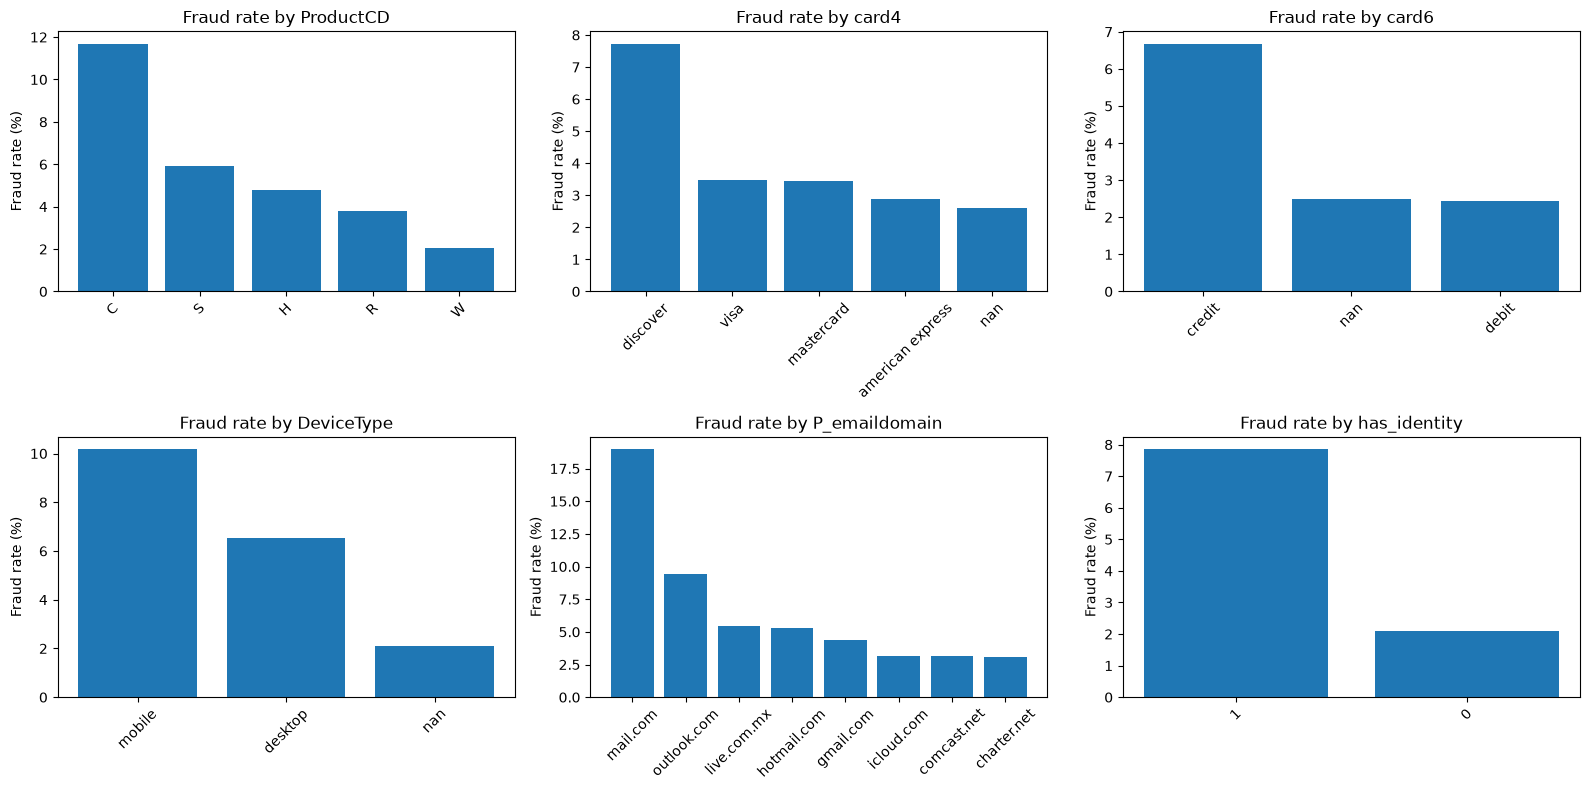

In [7]:
# Show fraud rates for common values of a selected column.
# We ignore groups with fewer than min_rows transactions because their rates can be misleading.
def plot_fraud_rate(column_name, axis, number_to_show=8, min_rows=500):
    grouped = data.groupby(column_name, dropna=False)["isFraud"].agg(
        fraud_rate="mean",
        transaction_count="size"
    )

    common_groups = grouped[grouped["transaction_count"] >= min_rows]
    highest_fraud_groups = common_groups.sort_values(
        "fraud_rate", ascending=False
    ).head(number_to_show)

    labels = [str(value) for value in highest_fraud_groups.index]
    rates = highest_fraud_groups["fraud_rate"] * 100

    axis.bar(labels, rates)
    axis.set_title(f"Fraud rate by {column_name}")
    axis.set_ylabel("Fraud rate (%)")
    axis.tick_params(axis="x", rotation=45)


columns_to_explore = [
    "ProductCD", "card4", "card6",
    "DeviceType", "P_emaildomain", "has_identity"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for axis, column_name in zip(axes.ravel(), columns_to_explore):
    plot_fraud_rate(column_name, axis)

plt.tight_layout()
plt.show()


## 4. Cleaning and simple feature engineering

Everything in this step is **row-wise** (each new value depends only on that row), so it cannot leak
information between train and test. Anything that needs statistics from the data (missing-rate
thresholds, category encodings) is deferred to section 5 and fitted on training data only.

Steps:
- Lower-case and strip all text columns (`"Visa"` and `"visa "` become the same value).
- `hour`, `day_of_week` from `TransactionDT`.
- `amt_log`, `amt_cents` from `TransactionAmt`.
- `email_match`: purchaser and recipient email domain are the same (1/0, NaN if one is missing).
- `browser_family`, `os_family`: strip version numbers from `id_31` / `id_30`
  (`"chrome 63.0"` becomes `"chrome"`).
- `n_missing`: number of missing values in the row (a cheap way to capture "how much info do we have").
- Drop `TransactionID` (just a key) and `TransactionDT` as a *feature*. We keep it only to build months.
  A raw time counter would never repeat in the future, so a model could not use it meaningfully.

In [8]:
# 4. Clean text values and create a few simple features
def clean_and_create_features(dataframe):
    # Work on a copy so the original dataframe is not changed unexpectedly.
    dataframe = dataframe.copy()

    # A. Clean text columns only.
    # Keep missing values as missing; lowercase and trim actual text values.
    text_columns = dataframe.select_dtypes(include=["object", "string", "category"]).columns

    for column in text_columns:
        dataframe[column] = dataframe[column].apply(
            lambda value: value.lower().strip() if isinstance(value, str) else value
        )

    # B. Count missing values in the original columns before adding new features.
    dataframe["n_missing"] = dataframe.isna().sum(axis=1).astype("int16")

    # C. Create time features from TransactionDT.
    # TransactionDT is measured in seconds.
    dataframe["hour"] = (
        (dataframe["TransactionDT"] // 3600) % 24
    ).astype("int8")

    dataframe["day_of_week"] = (
        (dataframe["TransactionDT"] // 86400) % 7
    ).astype("int8")

    # D. Create transaction amount features.
    dataframe["amt_log"] = np.log1p(dataframe["TransactionAmt"]).astype("float32")

    dataframe["amt_cents"] = (
        (dataframe["TransactionAmt"] * 100).round() % 100
    ).astype("float32")

    # E. Check whether the purchase email and recipient email domains match.
    both_emails_exist = (
        dataframe["P_emaildomain"].notna()
        & dataframe["R_emaildomain"].notna()
    )

    dataframe["email_match"] = np.where(
        both_emails_exist,
        (dataframe["P_emaildomain"] == dataframe["R_emaildomain"]).astype(float),
        np.nan
    ).astype("float32")

    # F. Simplify browser and operating-system names by removing version numbers.
    if "id_31" in dataframe.columns:
        dataframe["browser_family"] = dataframe["id_31"].str.replace(
            r"[\d\._]+", "", regex=True
        ).str.strip()

    if "id_30" in dataframe.columns:
        dataframe["os_family"] = dataframe["id_30"].str.replace(
            r"[\d\._]+", "", regex=True
        ).str.strip()

    return dataframe


# Run the cleaning and feature-creation steps
data = clean_and_create_features(data)

# Divide transactions into 30-day time blocks.
# Values after day 180 are grouped into the last block (month 5).
data["month"] = (
    data["TransactionDT"] // (30 * 86400)
).clip(upper=5).astype(int)

# Separate the answer we want to predict from the input features.
target = data["isFraud"].values
month = data["month"].values

# Remove identifiers, raw time, and target from the model inputs.
features = data.drop(
    columns=["isFraud", "TransactionID", "TransactionDT", "month"]
)

# Free memory; the separate target, month, and feature variables are ready.
del data


## 5. Preprocessing and the 6 monthly folds

**Folds.** The data is cut into 6 blocks of 30 days (fold 0 = oldest month, fold 5 = newest).
We use **forward chaining (expanding window)**:

| Round | Train on | Test on |
|---|---|---|
| 1 | month 0 | month 1 |
| 2 | months 0–1 | month 2 |
| 3 | months 0–2 | month 3 |
| 4 | months 0–3 | month 4 |
| 5 | months 0–4 | month 5 |

The model is never tested on data from before its training data, so there is no look-ahead.
Month 0 can only be used for training, which is why there are 5 test rounds rather than 6.

**No-leakage rules.** A `Preprocessor` object is **fitted on the training months only** and then applied to the
test month. It learns:
1. which columns to drop (more than 90% missing in train, or constant in train);
2. the integer code of each category (categories unseen in train become `-1`; missing becomes its own category).

Nothing from the test month (not even its labels or its missing rates) is used to build the preprocessing.
For the Decision Tree, missing numeric values are filled with a constant (`-999`), which needs no statistics. LightGBM handles
missing values natively, so it receives the NaNs as they are. Both models see exactly the same columns.

In [9]:
# 5. Preprocessing
# This class learns preprocessing rules from the training data only.
# The same rules are then applied to that fold's validation data.
class Preprocessor:
    def __init__(self, maximum_missing_rate=0.90):
        self.maximum_missing_rate = maximum_missing_rate

    def fit(self, training_features):
        # Keep columns that have at most 90% missing values
        # and contain more than one non-missing value.
        missing_rates = training_features.isna().mean()

        self.columns_to_keep = []
        for column in training_features.columns:
            has_too_many_missing = missing_rates[column] > self.maximum_missing_rate
            has_only_one_value = training_features[column].nunique(dropna=True) <= 1

            if not has_too_many_missing and not has_only_one_value:
                self.columns_to_keep.append(column)

        # Separate text/categorical columns from numeric columns.
        self.categorical_columns = [
            column for column in self.columns_to_keep
            if not pd.api.types.is_numeric_dtype(training_features[column])
        ]

        self.numeric_columns = [
            column for column in self.columns_to_keep
            if column not in self.categorical_columns
        ]

        # Learn category-to-number mappings using training data only.
        self.encoder = OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        )

        if self.categorical_columns:
            training_categories = (
                training_features[self.categorical_columns]
                .astype(object)
                .fillna("missing")
            )
            self.encoder.fit(training_categories)

        return self

    def transform(self, features_to_transform):
        # Keep numeric columns as they are.
        numeric_data = features_to_transform[self.numeric_columns].copy()

        # Convert categorical values to numbers using the mappings learned in fit().
        if self.categorical_columns:
            categorical_values = (
                features_to_transform[self.categorical_columns]
                .astype(object)
                .fillna("missing")
            )

            encoded_values = self.encoder.transform(categorical_values)

            categorical_data = pd.DataFrame(
                encoded_values,
                columns=self.categorical_columns,
                index=features_to_transform.index
            )
        else:
            categorical_data = pd.DataFrame(index=features_to_transform.index)

        # Join numeric and encoded categorical columns.
        processed_data = pd.concat([numeric_data, categorical_data], axis=1)

        # LightGBM and the tree model can work with this compact numeric format.
        return processed_data.astype("float32")


# Show the size and fraud percentage of each 30-day time block.
fold_information = (
    pd.DataFrame({"month": month, "isFraud": target})
    .groupby("month")["isFraud"]
    .agg(
        number_of_transactions="size",
        number_of_fraud_cases="sum",
        fraud_rate="mean"
    )
)

fold_information["fraud_rate"] = (fold_information["fraud_rate"] * 100).round(2)
fold_information


,number_of_transactions,number_of_fraud_cases,fraud_rate
month,,,
0,130968,3243,2.48
1,89838,3627,4.04
2,91768,3700,4.03
3,98027,3849,3.93
4,85303,2962,3.47
5,94636,3282,3.47


## 6. Models and evaluation

**Models**
- **Decision Tree (baseline):** simple, fast and interpretable. `max_depth=8`, `min_samples_leaf=100` to prevent
  overfitting (a fully grown tree memorises the training data).
- **LightGBM:** gradient-boosted trees, usually the strongest choice for tabular data. Handles missing values
  and many features efficiently. Fixed settings (300 trees, learning rate 0.05, 64 leaves, column/row
  subsampling). **No early stopping** on the test month, since that would leak test information into training.
  No hyper-parameter tuning is done, to keep the project simple.

We do **not** re-balance the classes (no oversampling or class weights). The chosen metrics are
threshold-free or rank-based, so this keeps the predicted probabilities honest.

**Metrics** (because only about 3.5% of transactions are fraud):
- **ROC-AUC**: probability that a random fraud is scored higher than a random legitimate transaction (the Kaggle metric).
  It can look flattering under heavy imbalance.
- **PR-AUC (average precision)**: summarises the precision/recall trade-off on the fraud class. A random model scores
  about the fraud rate (about 0.035), so this metric is much more demanding.
- **Recall@1% and Precision@1%**: imagine analysts can review only the 1% highest-scored transactions.
  Recall@1% = share of all frauds caught in that 1%. Precision@1% = share of reviewed transactions that are really fraud.
  This is a practical, threshold-free way to measure business value.

In [ ]:
# 6. Define how we measure model performance
def calculate_metrics(actual_values, fraud_scores, top_percentage=0.01):
    # Find how many transactions are in the highest-scored 1%.
    number_to_review = max(1, int(len(actual_values) * top_percentage))

    # Get the positions of the transactions with the highest fraud scores.
    highest_scores_positions = np.argsort(-fraud_scores, kind="stable")[:number_to_review]

    # Recall@1%: what fraction of all fraud cases appears in that top 1%?
    recall_at_top = (
        actual_values[highest_scores_positions].sum() / actual_values.sum()
    )

    return {
        "roc_auc": roc_auc_score(actual_values, fraud_scores),
        "pr_auc": average_precision_score(actual_values, fraud_scores),
        "recall@1%": recall_at_top
    }


# Create both models with their settings in one place.
def create_models():
    decision_tree = DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=100,
        random_state=SEED
    )

    lightgbm_model = lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=64,
        min_child_samples=50,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.5,
        random_state=SEED,
        n_jobs=-1,
        verbose=-1
    )

    return {
        "Decision Tree": decision_tree,
        "LightGBM": lightgbm_model
    }


# 7. Train and evaluate both models using forward-chaining validation.
# For each round, train on earlier months and test on the next month.
all_results = []
last_round_models = {}

for test_month in range(1, 6):
    training_rows = month < test_month
    testing_rows = month == test_month

    # Fit preprocessing only on the training months to avoid data leakage.
    preprocessor = Preprocessor().fit(features[training_rows])

    training_features = preprocessor.transform(features[training_rows])
    testing_features = preprocessor.transform(features[testing_rows])

    training_target = target[training_rows]
    testing_target = target[testing_rows]

    # Train and evaluate each model using the same training and testing rows.
    for model_name, model in create_models().items():

        if model_name == "Decision Tree":
            # Scikit-learn's Decision Tree needs missing numeric values filled.
            model.fit(training_features.fillna(-999), training_target)
            fraud_scores = model.predict_proba(
                testing_features.fillna(-999)
            )[:, 1]

        else:
            # LightGBM can handle missing values directly.
            model.fit(training_features, training_target)
            fraud_scores = model.predict_proba(testing_features)[:, 1]

        # Save the results for this model and month.
        model_metrics = calculate_metrics(testing_target, fraud_scores)

        all_results.append({
            "test_month": test_month,
            "model": model_name,
            "fraud_rate_test": testing_target.mean(),
            **model_metrics
        })

        # Keep the models from the final round for feature-importance plots.
        last_round_models[model_name] = (model, list(training_features.columns))

    print(
        f"Finished month {test_month}: "
    )

results = pd.DataFrame(all_results)
results.round(4)


Finished month 1: 130,968 training rows, 428 features
Finished month 2: 220,806 training rows, 428 features
Finished month 3: 312,574 training rows, 427 features
Finished month 4: 410,601 training rows, 427 features
Finished month 5: 495,904 training rows, 428 features


,test_month,model,n_train,n_test,fraud_rate_test,roc_auc,pr_auc,recall@1%
0,1,Decision Tree,130968,89838,0.0404,0.8130,0.3975,0.2068
1,1,LightGBM,130968,89838,0.0404,0.9091,0.6012,0.2401
2,2,Decision Tree,220806,91768,0.0403,0.8088,0.4080,0.2114
3,2,LightGBM,220806,91768,0.0403,0.9170,0.6470,0.2427
4,3,Decision Tree,312574,98027,0.0393,0.7761,0.3787,0.2206
5,3,LightGBM,312574,98027,0.0393,0.9127,0.5875,0.2380
6,4,Decision Tree,410601,85303,0.0347,0.8115,0.3668,0.2255
7,4,LightGBM,410601,85303,0.0347,0.9257,0.6064,0.2657
8,5,Decision Tree,495904,94636,0.0347,0.7940,0.3433,0.2124
9,5,LightGBM,495904,94636,0.0347,0.9228,0.5858,0.2608


roc_auc          pr_auc         recall@1%        
                 mean     std    mean     std      mean     std
model                                                          
Decision Tree  0.8007  0.0157  0.3789  0.0255    0.2153  0.0076
LightGBM       0.9175  0.0069  0.6056  0.0247    0.2495  0.0128

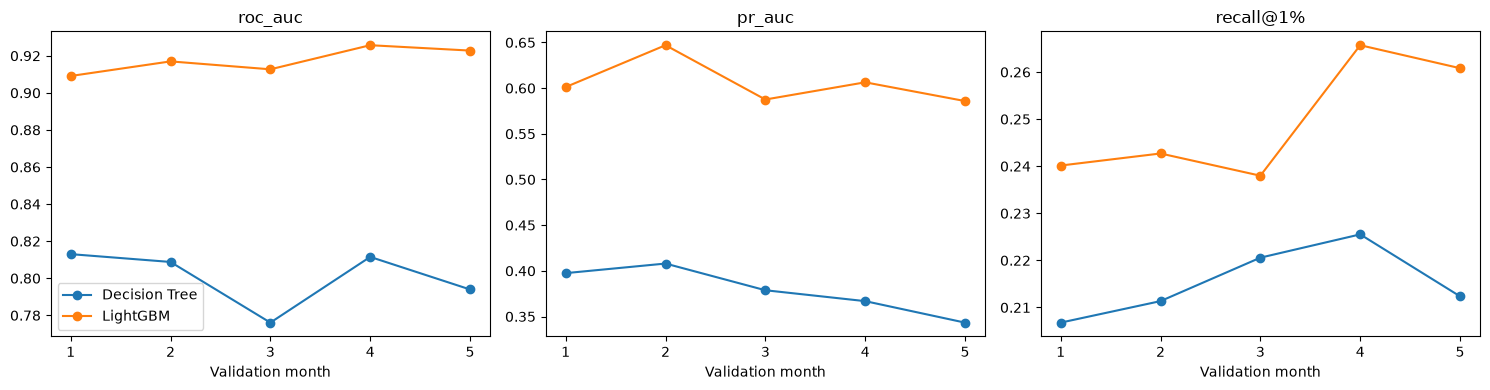

LightGBM has a higher PR-AUC in 5 out of 5 validation months.


In [11]:
# 8. Compare average performance across all validation months.
metrics_to_compare = ["roc_auc", "pr_auc", "recall@1%"]

summary = (
    results.groupby("model")[metrics_to_compare]
    .agg(["mean", "std"])
    .round(4)
)

display(summary)

# Plot each metric across the five validation months.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for axis, metric_name in zip(axes, metrics_to_compare):
    for model_name, model_results in results.groupby("model"):
        axis.plot(
            model_results["test_month"],
            model_results[metric_name],
            marker="o",
            label=model_name
        )

    axis.set_title(metric_name)
    axis.set_xlabel("Validation month")
    axis.set_xticks(range(1, 6))

axes[0].legend()
plt.tight_layout()
plt.show()

# Count how many months LightGBM achieved a higher PR-AUC than the Decision Tree.
pr_auc_by_month = results.pivot(
    index="test_month",
    columns="model",
    values="pr_auc"
)

number_of_lightgbm_wins = (
    pr_auc_by_month["LightGBM"] > pr_auc_by_month["Decision Tree"]
).sum()

print(
    "LightGBM has a higher PR-AUC in",
    int(number_of_lightgbm_wins),
    "out of",
    len(pr_auc_by_month),
    "validation months."
)


### Which features matter?
Feature importance from the models trained on the **last round** (months 0–4). Importance shows what the model *uses*,
not causal proof of what causes fraud.

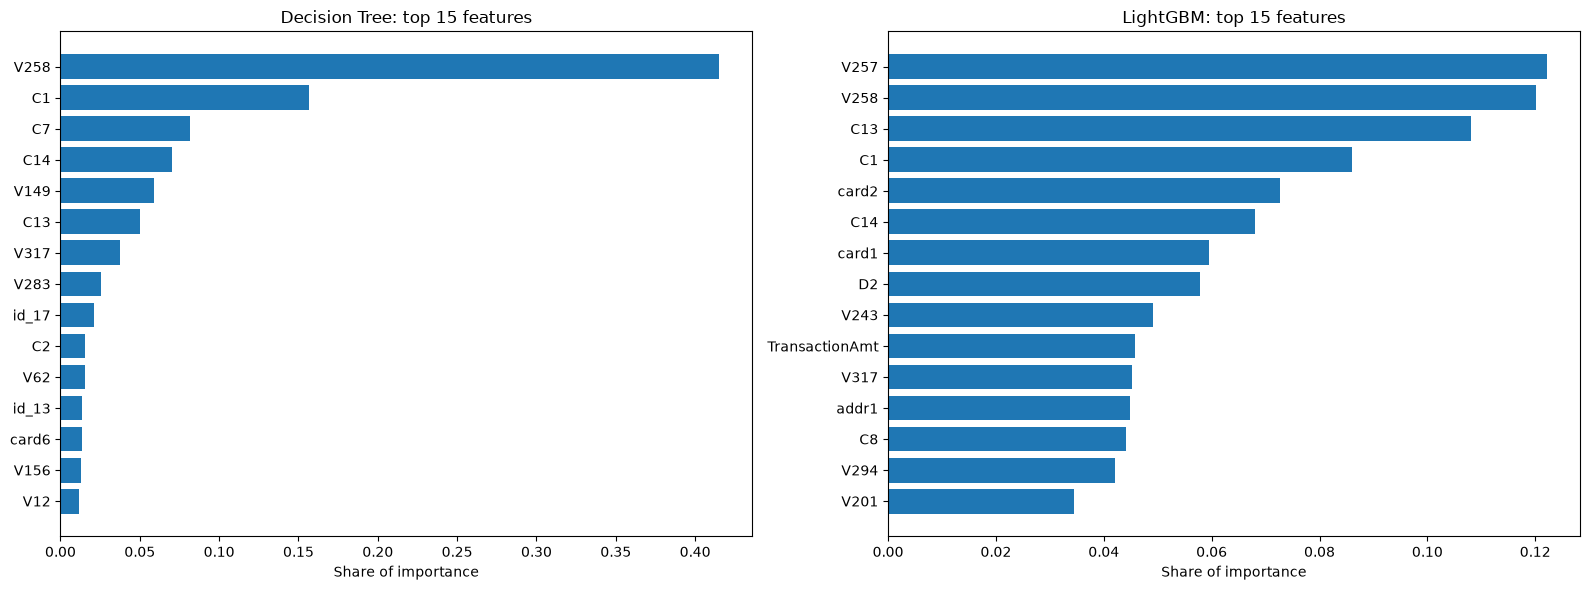

In [12]:
# 9. See which features each model relied on most in the final validation round.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for axis, model_name in zip(axes, ["Decision Tree", "LightGBM"]):
    model, feature_names = last_round_models[model_name]

    if model_name == "LightGBM":
        importance_values = model.booster_.feature_importance(importance_type="gain")
    else:
        importance_values = model.feature_importances_

    # Pair each feature name with its importance score.
    importance = pd.Series(importance_values, index=feature_names)

    # Keep the 15 most important features and display them from low to high.
    top_features = (
        importance.sort_values(ascending=False)
        .head(15)
        .sort_values()
    )

    # Convert scores into shares so they are easier to compare.
    importance_share = top_features / top_features.sum()

    axis.barh(importance_share.index, importance_share.values)
    axis.set_title(f"{model_name}: top 15 features")
    axis.set_xlabel("Share of importance")

plt.tight_layout()
plt.show()


## 7. Interpretation of results

**How to read the numbers**
- Compare models **fold by fold** and look at the **mean and standard deviation** across folds. A gap that is larger than the fold-to-fold
  variation is more convincing than a small gap in a single fold.
- ROC-AUC will look high for both models, since fraud is rare and many legitimate transactions are easy to rank low.
  Rely more on **PR-AUC** and **Recall@1%**, which reflect how well the model finds the rare fraud class.
- Remember the reference point: a random model has PR-AUC ≈ fraud rate (about 0.035).

**What we expect (to be confirmed or rejected by your run):** LightGBM should outperform the single tree on every
metric, because boosting combines many trees and captures interactions between the hundreds of anonymised
features, whereas one shallow tree uses only a handful of splits. The tree is still a useful baseline since it is
fast and easy to explain.

**Discussion points to write up after running**
- Did LightGBM win in every fold? By how much in PR-AUC and Recall@1%?
- Do results change between folds (e.g. later months being easier or harder)? This reflects drift in fraud patterns.
- Which features were most important in each model? Are they the ones identified in section 3?

**Limitations**
- No hyper-parameter tuning, so both models could be improved (especially LightGBM).
- Most features are anonymised, so we cannot give business explanations for them.
- Months are approximate 30-day blocks. Only 5 test rounds, so uncertainty estimates are rough.
- We did not use powerful but more complex ideas from the Kaggle competition (client "UID" reconstruction, aggregations on card/address groups).
  Those would improve scores but would need careful leakage control, and they are outside the scope of this project.
- The test set of the original competition is unlabelled, so our scores are **not** comparable with Kaggle leaderboard scores.